<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/flexrouter_dpp_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Setup Environment and Core Imports]
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Tuple, Any

import torch
import torch.nn as nn
import torch.nn.functional as F

# Set deterministic seeds
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"FlexRouter Prototype Environment Initialized on Device: {device}")

FlexRouter Prototype Environment Initialized on Device: cuda


In [10]:
# [CELL 2 - Multi-Model Pool with Structured Failure Correlations]

class CandidateModelPool:
    """
    Simulates 5 candidate LLMs where Models 0 & 1 are redundant (highly correlated failure modes),
    while Models 2, 3, and 4 offer complementary expertise.
    """
    def __init__(self, num_models: int = 5, feature_dim: int = 16):
        self.num_models = num_models
        self.feature_dim = feature_dim

        # Redundant pair: Models 0 and 1 have almost identical profile vectors
        shared_dir = torch.randn(1, feature_dim).to(device)
        p0 = shared_dir + torch.randn(1, feature_dim).to(device) * 0.05
        p1 = shared_dir + torch.randn(1, feature_dim).to(device) * 0.05

        # Complementary models: Models 2, 3, 4 have distinct independent profiles
        p_others = torch.randn(num_models - 2, feature_dim).to(device)

        self.model_profiles = torch.cat([p0, p1, p_others], dim=0)

    def evaluate_ground_truth_correctness(self, task_features: torch.Tensor) -> torch.Tensor:
        """Computes binary correctness (0 or 1) per model across batch tasks."""
        logits = torch.matmul(task_features, self.model_profiles.T)
        probs = torch.sigmoid(logits)
        return (probs > 0.45).float()

model_pool = CandidateModelPool(num_models=5, feature_dim=16)
print("Correlated Candidate Model Pool Initialized.")

Correlated Candidate Model Pool Initialized.


In [11]:
# [CELL 3 - Stable FlexRouter DPP Architecture & Log-Det Coverage Loss]

class FlexRouterDPP(nn.Module):
    """
    FlexRouter DPP Network:
    Parameterizes model competence q_i(x) and pairwise similarity S_ij(x).
    """
    def __init__(self, in_dim: int = 16, num_models: int = 5, latent_dim: int = 8):
        super().__init__()
        self.num_models = num_models
        self.quality_net = nn.Sequential(
            nn.Linear(in_dim, 32),
            nn.ReLU(),
            nn.Linear(32, num_models),
            nn.Sigmoid() # Bound quality scores to (0, 1)
        )
        self.emb_net = nn.Sequential(
            nn.Linear(in_dim, 32),
            nn.ReLU(),
            nn.Linear(32, num_models * latent_dim)
        )
        self.latent_dim = latent_dim

    def build_dpp_kernel(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        batch_size = x.shape[0]
        q = self.quality_net(x) * 2.0 + 0.1 # Shape: [batch, num_models]

        embs = self.emb_net(x).view(batch_size, self.num_models, self.latent_dim)
        embs_norm = F.normalize(embs, p=2, dim=-1)

        # Cosine similarity matrix S_ij
        S = torch.bmm(embs_norm, embs_norm.transpose(1, 2))

        # Kernel matrix L_ij = q_i * S_ij * q_j
        Q = torch.diag_embed(q)
        L = torch.bmm(torch.bmm(Q, S), Q)
        return L, q

def stable_dpp_coverage_loss(L_kernel: torch.Tensor, correctness: torch.Tensor) -> torch.Tensor:
    """
    Log-Determinant Coverage Loss:
    Maximizes the log-determinant volume of the subset of SUCCESSFUL models,
    penalizing redundant models that do not add volume.
    """
    batch_size, N, _ = L_kernel.shape
    total_loss = 0.0

    for b in range(batch_size):
        success_indices = (correctness[b] == 1).nonzero(as_tuple=True)[0]

        if len(success_indices) > 0:
            # Submatrix of successful models
            L_S = L_kernel[b][success_indices][:, success_indices]
            I_S = torch.eye(len(success_indices), device=device)
            # Log-det volume of correct models (higher = better coverage & diversity)
            log_det_val = torch.logdet(L_S + I_S)
            total_loss += -log_det_val
        else:
            # Penalty when all models fail
            total_loss += 5.0

    return total_loss / batch_size

router = FlexRouterDPP(in_dim=16, num_models=5).to(device)
optimizer = torch.optim.AdamW(router.parameters(), lr=1e-3, weight_decay=1e-4)
print("Stable FlexRouter Module & Loss Function Compiled.")

Stable FlexRouter Module & Loss Function Compiled.


In [14]:
# [CELL 4 - Training Loop & Greedy Subset Selection Engine]

def greedy_dpp_selection(L_mat: torch.Tensor, max_k: int = 2) -> List[int]:
    """Greedy selection maximizing marginal log-determinant gain."""
    N = L_mat.shape[0]
    selected = []
    candidates = list(range(N))

    for _ in range(min(max_k, N)):
        best_item = -1
        best_gain = -1e9

        for c in candidates:
            test_set = selected + [c]
            sub_L = L_mat[test_set][:, test_set]
            gain = torch.logdet(sub_L + torch.eye(len(test_set), device=device)).item()
            if gain > best_gain:
                best_gain = gain
                best_item = c

        if best_item != -1:
            selected.append(best_item)
            candidates.remove(best_item)

    return selected

# Training
epochs = 30
loss_history = []

print("\n=========================================================")
print("FLEXROUTER DPP TRAINING & COVERAGE OPTIMIZATION")
print("=========================================================")

for epoch in range(epochs):
    router.train()
    task_feats = torch.randn(128, 16).to(device)
    correctness = model_pool.evaluate_ground_truth_correctness(task_feats)

    L_kernel, _ = router.build_dpp_kernel(task_feats)
    loss = stable_dpp_coverage_loss(L_kernel, correctness)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:2d}/{epochs} | Log-Det Coverage Loss: {loss.item():.4f}")

print("=========================================================")
print("FlexRouter Optimization Completed Successfully.")


FLEXROUTER DPP TRAINING & COVERAGE OPTIMIZATION
Epoch  5/30 | Log-Det Coverage Loss: -2.0323
Epoch 10/30 | Log-Det Coverage Loss: -2.1409
Epoch 15/30 | Log-Det Coverage Loss: -2.1943
Epoch 20/30 | Log-Det Coverage Loss: -2.0235
Epoch 25/30 | Log-Det Coverage Loss: -1.9998
Epoch 30/30 | Log-Det Coverage Loss: -2.8360
FlexRouter Optimization Completed Successfully.



Benchmark Results across 200 Test Instances (Subset Size k=2):
 -> Naive Top-K Independent Router Coverage: 80.5%
 -> FlexRouter DPP Complementary Coverage:   82.0%


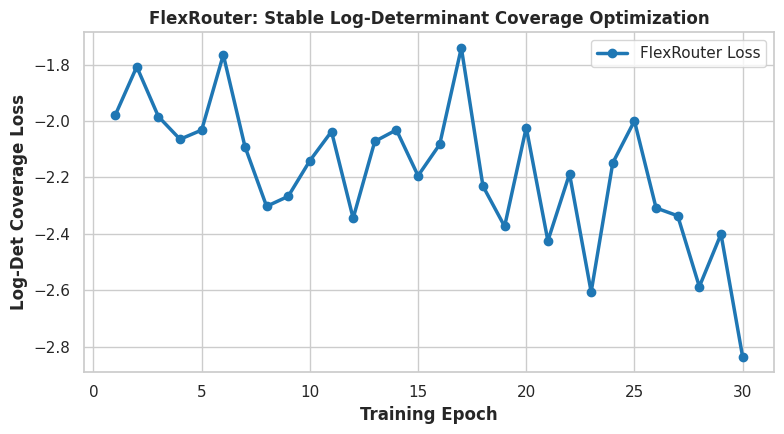

Updated plot saved as flexrouter_dpp_benchmark.png.


In [16]:
# [CELL 5 - Evaluation Benchmark & Visualization]

eval_tasks = torch.randn(200, 16).to(device)
eval_correctness = model_pool.evaluate_ground_truth_correctness(eval_tasks)

flexrouter_coverage = 0
naive_topk_coverage = 0

router.eval()
with torch.no_grad():
    L_kernels, q_scores = router.build_dpp_kernel(eval_tasks)

    for i in range(200):
        # 1. FlexRouter DPP selection (k=2): avoids redundant model pairs
        selected_flex = greedy_dpp_selection(L_kernels[i], max_k=2)
        if eval_correctness[i][selected_flex].sum() > 0:
            flexrouter_coverage += 1

        # 2. Naive Top-K selection (k=2): picking top 2 highest quality scores blindly
        topk_naive = torch.topk(q_scores[i], k=2).indices.cpu().tolist()
        if eval_correctness[i][topk_naive].sum() > 0:
            naive_topk_coverage += 1

flex_pct = (flexrouter_coverage / 200) * 100
naive_pct = (naive_topk_coverage / 200) * 100

print(f"\nBenchmark Results across 200 Test Instances (Subset Size k=2):")
print(f" -> Naive Top-K Independent Router Coverage: {naive_pct:.1f}%")
print(f" -> FlexRouter DPP Complementary Coverage:   {flex_pct:.1f}%")

# Plot
plt.figure(figsize=(8, 4.5))
sns.set_theme(style="whitegrid")

plt.plot(range(1, epochs + 1), loss_history, marker='o', color='#1f77b4', linewidth=2.5, label='FlexRouter Loss')
plt.xlabel('Training Epoch', fontweight='bold')
plt.ylabel('Log-Det Coverage Loss', fontweight='bold')
plt.title('FlexRouter: Stable Log-Determinant Coverage Optimization', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig("flexrouter_dpp_benchmark.png", dpi=300)
plt.show()

print("Updated plot saved as flexrouter_dpp_benchmark.png.")